# 💧 Water Potability Classification

## Dataset Description

This dataset contains several water quality measurements used to determine whether water is safe for human consumption.

| Column | Description | Type |
|---|---|---|
| **ph** | pH level of the water | Numerical |
| **Hardness** | Water hardness | Numerical |
| **Solids** | Total dissolved solids in the water | Numerical |
| **Chloramines** | Amount of chloramines in the water | Numerical |
| **Sulfate** | Amount of sulfate in the water | Numerical |
| **Conductivity** | Electrical conductivity of the water | Numerical |
| **Organic_carbon** | Amount of organic carbon in the water | Numerical |
| **Trihalomethanes** | Amount of trihalomethanes in the water | Numerical |
| **Turbidity** | Water turbidity | Numerical |
| **Potability** | Indicates whether the water is safe for drinking | Binary / Target |


## 1. Imports

In [32]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from IPython.display import display

## 2. Load Dataset

In [33]:
df = pd.read_csv("water_potability.csv")

display(df.head())
print("Shape:", df.shape)
df.info()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Shape: (3276, 10)
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [34]:
data_description = pd.DataFrame({
    "Column": [
        "ph",
        "Hardness",
        "Solids",
        "Chloramines",
        "Sulfate",
        "Conductivity",
        "Organic_carbon",
        "Trihalomethanes",
        "Turbidity",
        "Potability"
    ],
    
    "Description": [
        "pH level of the water",
        "Water hardness",
        "Total dissolved solids in the water",
        "Amount of chloramines in the water",
        "Amount of sulfate in the water",
        "Electrical conductivity of the water",
        "Amount of organic carbon in the water",
        "Amount of trihalomethanes in the water",
        "Water turbidity",
        "Indicates whether the water is potable or not"
    ],
    
    "Type": [
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Binary / Target"
    ]
})

display(data_description)

,Column,Description,Type
0,ph,pH level of the water,Numerical
1,Hardness,Water hardness,Numerical
2,Solids,Total dissolved solids in the water,Numerical
3,Chloramines,Amount of chloramines in the water,Numerical
4,Sulfate,Amount of sulfate in the water,Numerical
5,Conductivity,Electrical conductivity of the water,Numerical
6,Organic_carbon,Amount of organic carbon in the water,Numerical
7,Trihalomethanes,Amount of trihalomethanes in the water,Numerical
8,Turbidity,Water turbidity,Numerical
9,Potability,Indicates whether the water is potable or not,Binary / Target


## 3. Data Understanding

In [35]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["Potability"].value_counts())

print("\nTarget distribution (%):")
display(df["Potability"].value_counts(normalize=True).mul(100).round(2))

Missing values:


ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


Duplicates: 0

Target distribution:


Potability
0    1998
1    1278
Name: count, dtype: int64


Target distribution (%):


Potability
0    60.99
1    39.01
Name: proportion, dtype: float64

In [36]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


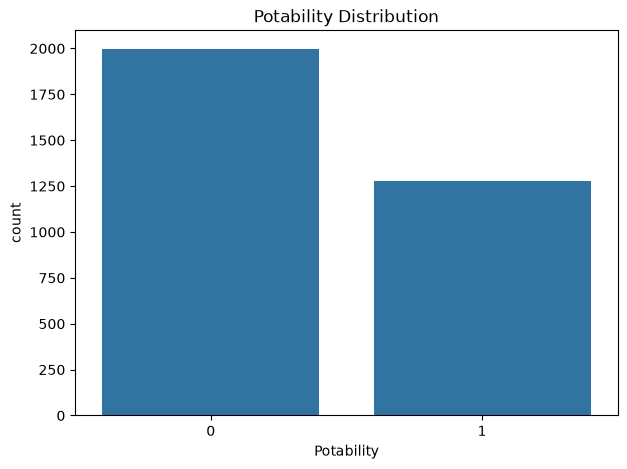

In [37]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Potability")
plt.title("Potability Distribution")
plt.show()

## 6. Histograms

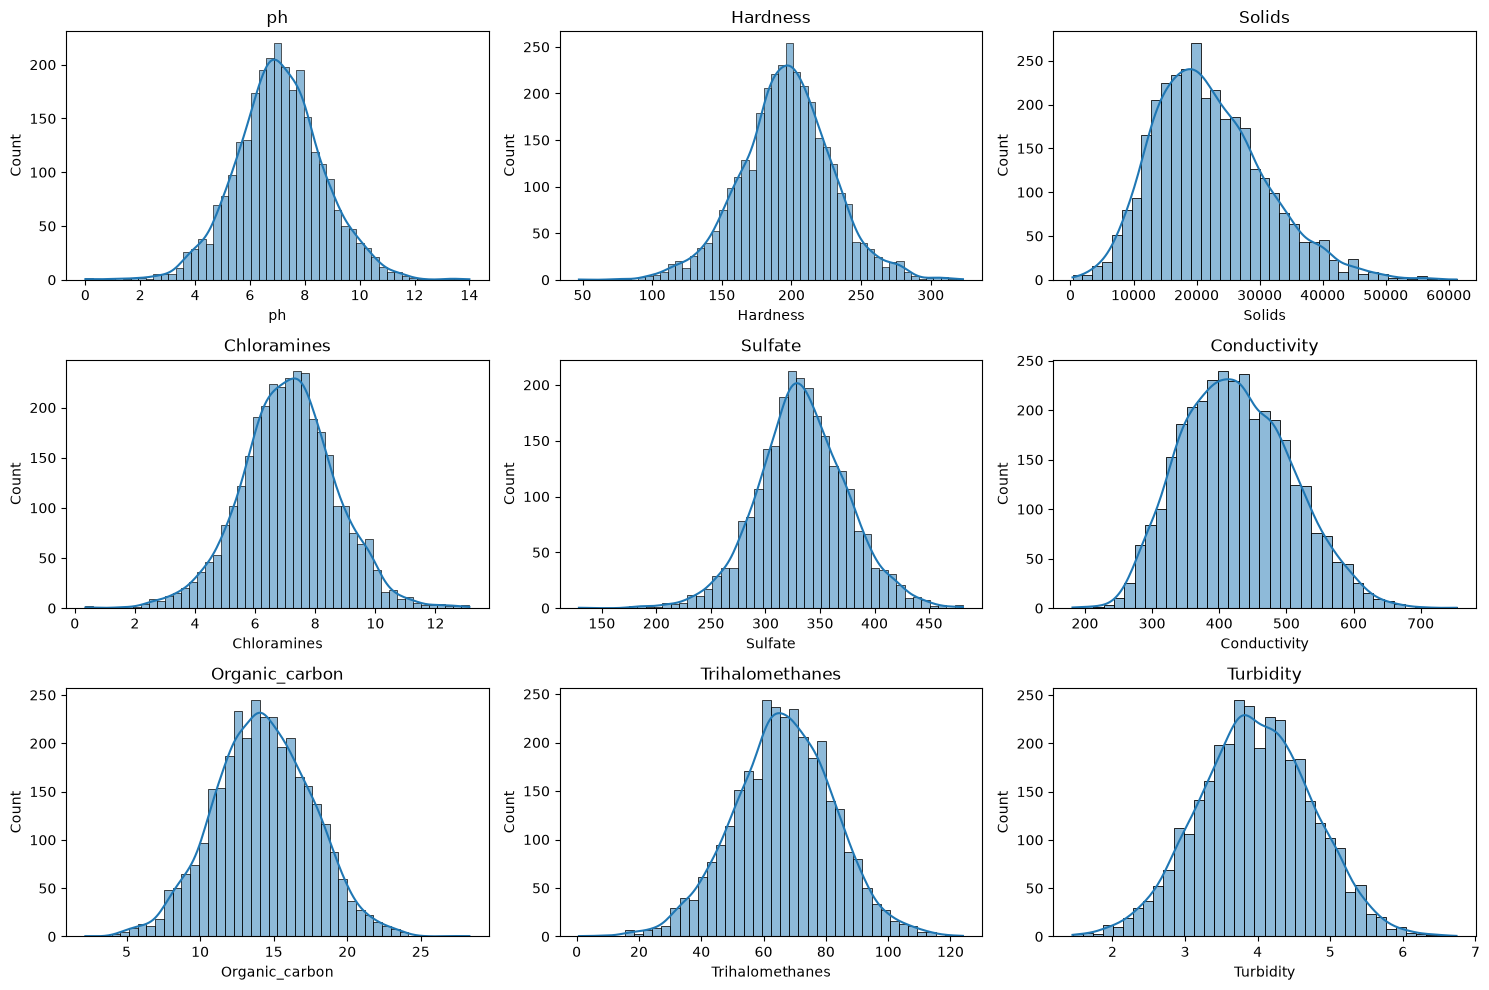

In [38]:
features = df.drop(columns="Potability").columns

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for i, column in enumerate(features):
    sns.histplot(df[column], kde=True, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(column)

plt.tight_layout()
plt.show()

## 7. Boxplots — Outliers Are NOT Removed

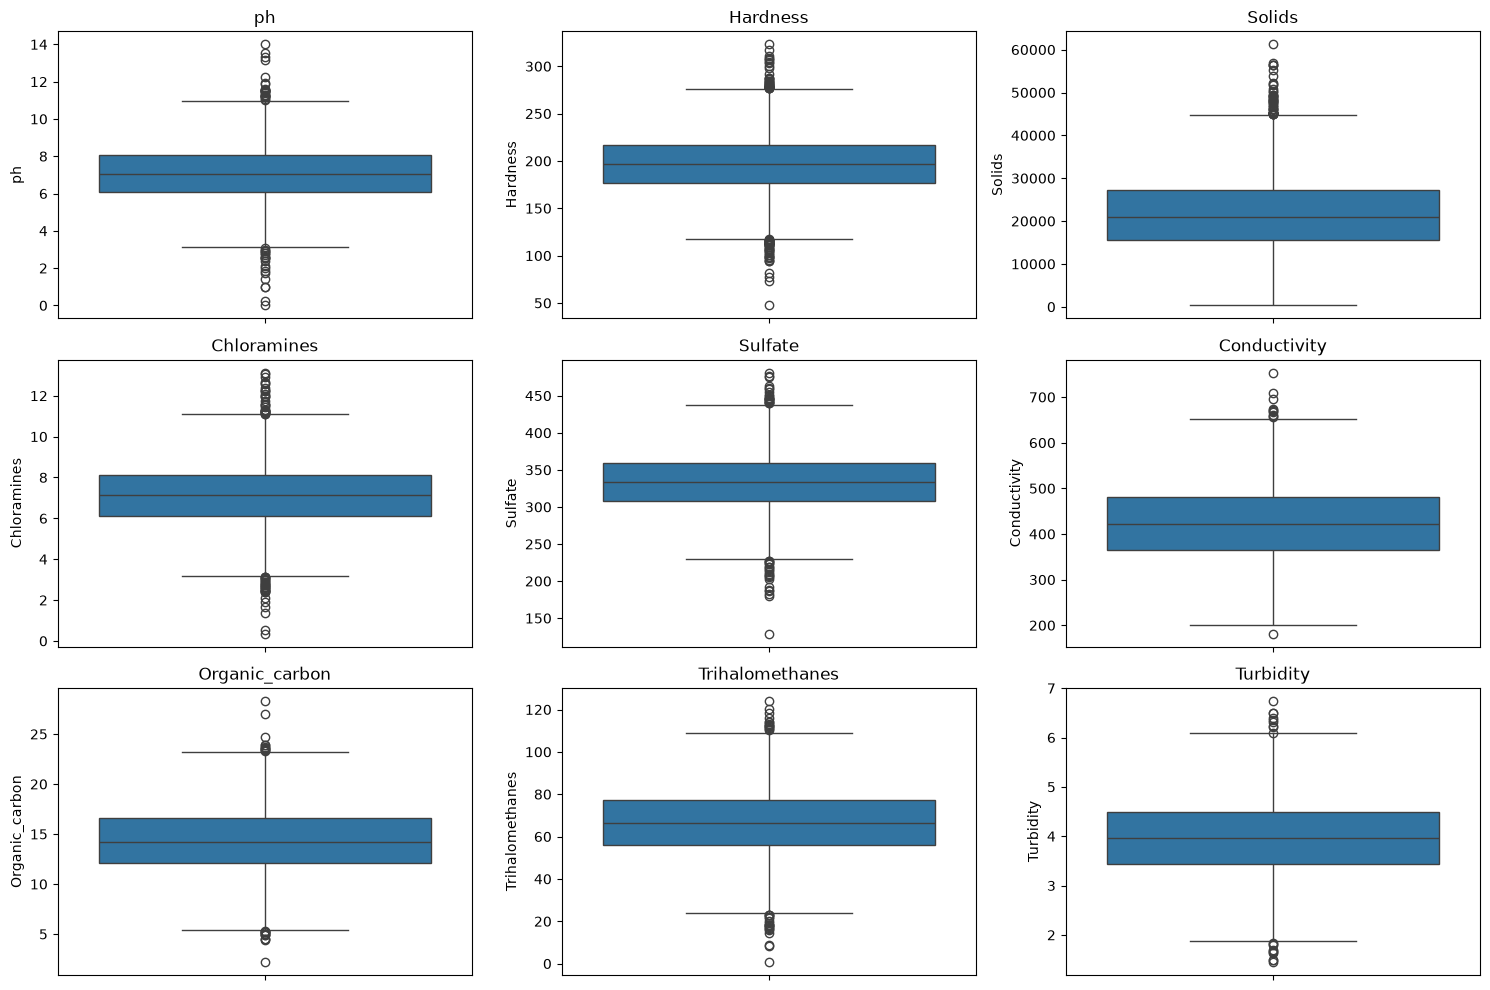

Outliers are intentionally kept in this project.


In [39]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for i, column in enumerate(features):
    sns.boxplot(y=df[column], ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(column)

plt.tight_layout()
plt.show()

print("Outliers are intentionally kept in this project.")

## 8. Correlation Heatmap

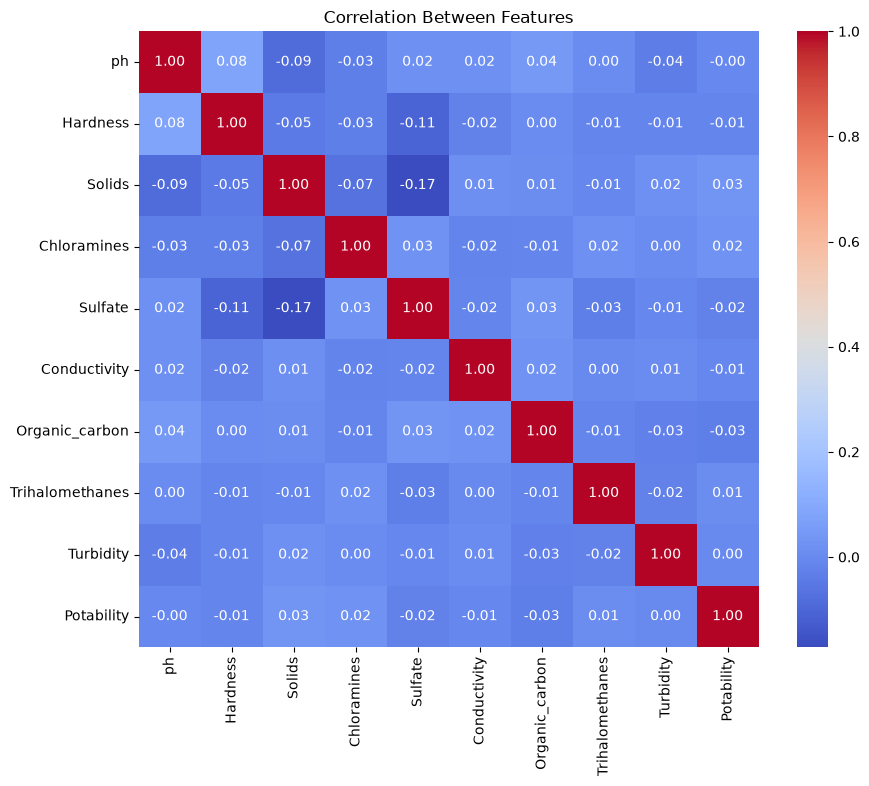

In [40]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Between Features")
plt.show()

## 9. Train / Test Split

In [41]:
X = df.drop(columns="Potability")
y = df["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=100,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (2620, 9)
X_test : (656, 9)
y_train: (2620,)
y_test : (656,)


## 10. Preprocessing Pipeline

In [42]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

## 11. Models

In [43]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=100),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=100),
    "Random Forest": RandomForestClassifier(random_state=100, n_jobs=-1),
    "SVM": SVC(probability=True, random_state=100),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=100),
    "AdaBoost": AdaBoostClassifier(random_state=100),
    "Extra Trees": ExtraTreesClassifier(random_state=100, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=100, eval_metric="logloss", n_jobs=-1),
    "LightGBM": LGBMClassifier(random_state=100, verbosity=-1, n_jobs=-1)
}

print("Number of models:", len(models))
print("\n".join(models.keys()))

Number of models: 11
Logistic Regression
KNN
Decision Tree
Random Forest
SVM
Naive Bayes
Gradient Boosting
AdaBoost
Extra Trees
XGBoost
LightGBM


## 12. Train All Models + Evaluation

In [44]:
results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, model in tqdm(models.items(), desc="Training models"):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "AP": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("F1 Score", ascending=False).reset_index(drop=True))

Training models: 100%|██████████| 11/11 [00:04<00:00,  2.30it/s]


,Model,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,ROC-AUC,AP
0,LightGBM,0.675305,0.630303,0.406250,0.494062,0.626875,0.692910,0.602908
1,XGBoost,0.652439,0.576923,0.410156,0.479452,0.608828,0.674590,0.560618
2,KNN,0.631098,0.534653,0.421875,0.471616,0.593438,0.643027,0.509745
3,Decision Tree,0.567073,0.450000,0.492188,0.470149,0.553594,0.553594,0.419655
4,SVM,0.687500,0.762887,0.289062,0.419263,0.615781,0.714629,0.641100
5,Random Forest,0.666159,0.655462,0.304688,0.416000,0.601094,0.707612,0.618689
6,Extra Trees,0.672256,0.688073,0.292969,0.410959,0.603984,0.707407,0.612536
7,Gradient Boosting,0.646341,0.611111,0.257812,0.362637,0.576406,0.678662,0.573983
8,Naive Bayes,0.626524,0.557895,0.207031,0.301994,0.551016,0.581104,0.495337
9,AdaBoost,0.605183,0.477612,0.125000,0.198142,0.518750,0.545791,0.423192


## 13. Model Comparison Plot

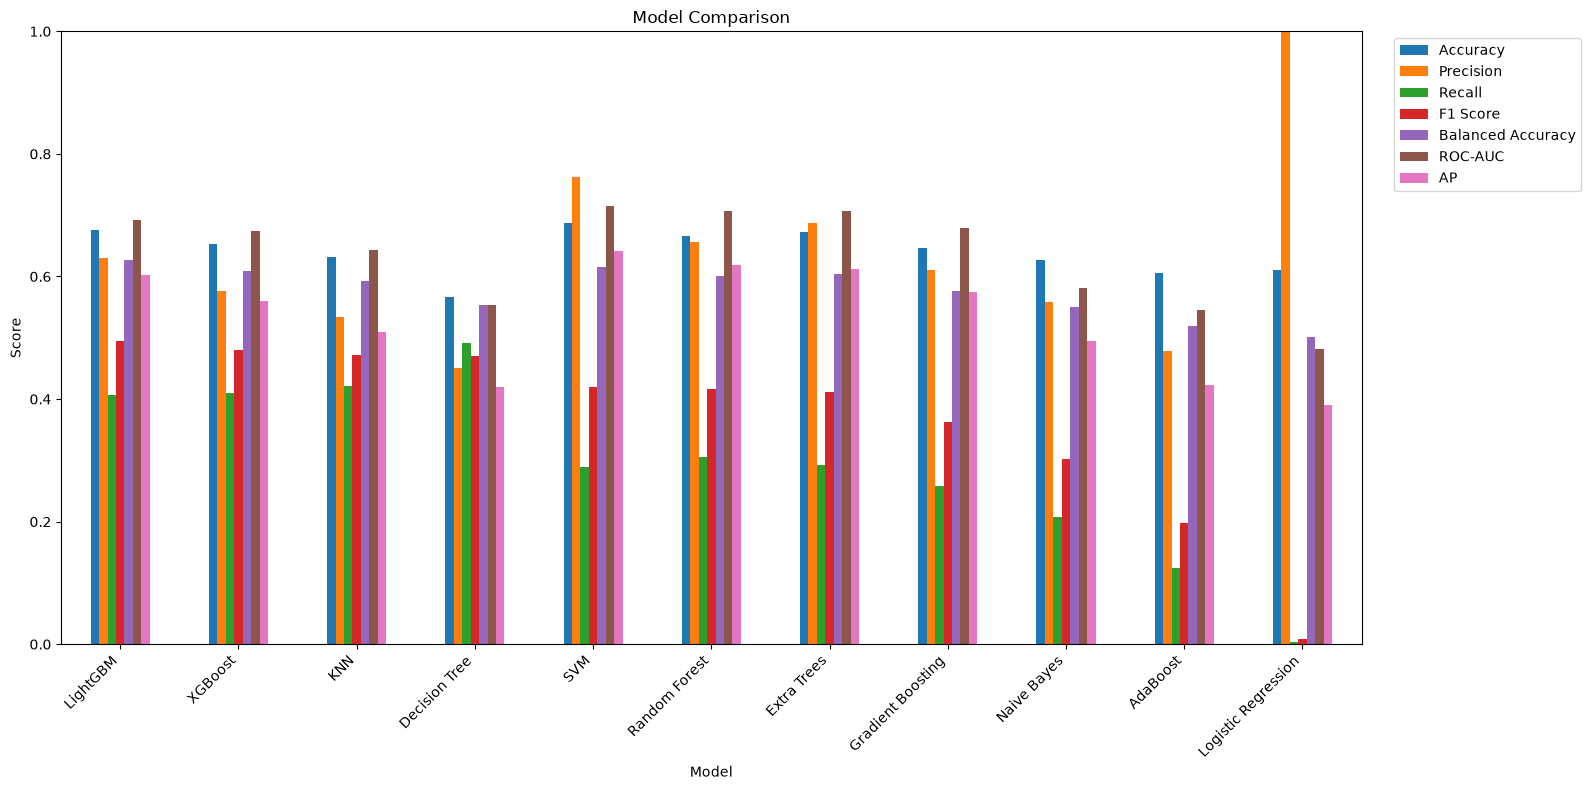

In [45]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Balanced Accuracy",
    "ROC-AUC",
    "AP"
]

results_df_sorted = results_df.sort_values("F1 Score", ascending=False).reset_index(drop=True)

results_df_sorted.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(16, 8)
)

plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 14. Confusion Matrix — Every Model

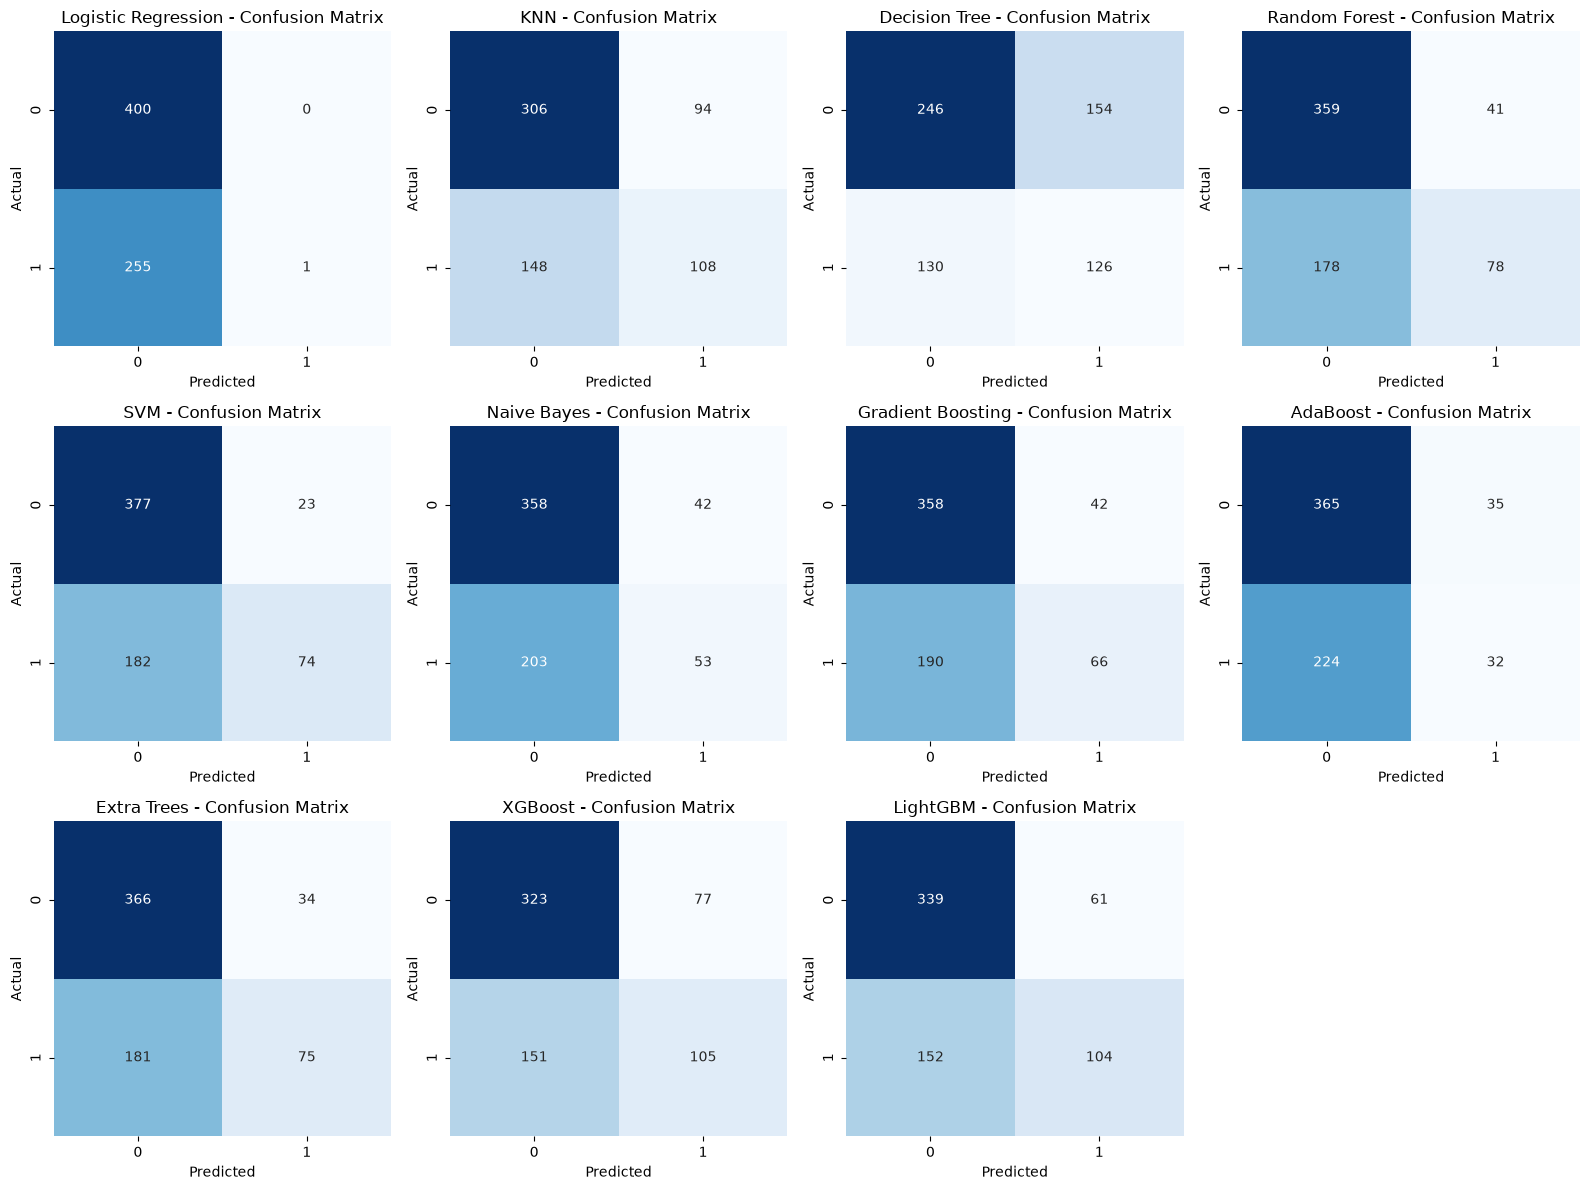

In [46]:
n_models = len(predictions)
n_cols = 4
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 16. ROC Curves + ROC-AUC

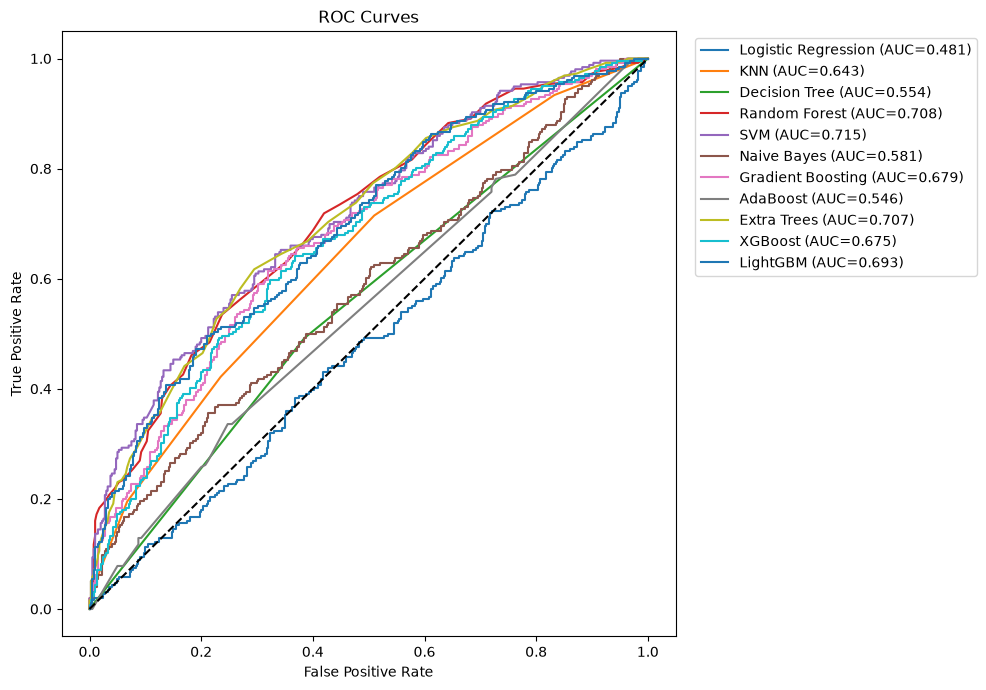

In [48]:
plt.figure(figsize=(10, 7))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 17. Precision-Recall Curves + Average Precision

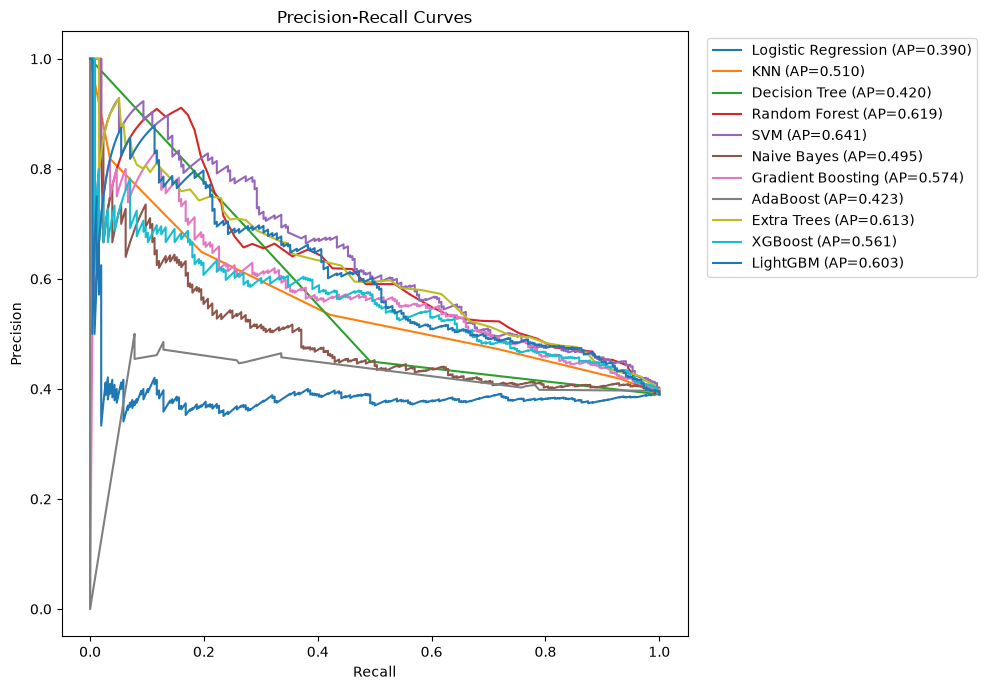

In [49]:
plt.figure(figsize=(10, 7))

for name, y_prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 18. GridSearchCV

Hyperparameter tuning is performed with Stratified Cross-Validation. The test set is not used for selecting parameters.

In [50]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=100)

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__solver": ["liblinear"]
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 11],
        "model__weights": ["uniform", "distance"]
    },
    "Decision Tree": {
        "model__max_depth": [None, 3, 5, 10, 15],
        "model__min_samples_split": [2, 5, 10]
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2]
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["rbf", "linear"],
        "model__gamma": ["scale"]
    },
    "Naive Bayes": {
        "model__var_smoothing": [1e-11, 1e-9, 1e-7]
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3]
    },
    "AdaBoost": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1, 0.5]
    },
    "Extra Trees": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2]
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.03, 0.1],
        "model__subsample": [0.8, 1.0]
    },
    "LightGBM": {
        "model__n_estimators": [100, 200],
        "model__num_leaves": [15, 31],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [-1, 10]
    }
}

In [51]:
grid_results = []
best_estimators = {}

for name, model in tqdm(models.items(), desc="GridSearchCV"):

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X_train, y_train)

    best_estimators[name] = grid.best_estimator_

    y_pred = grid.best_estimator_.predict(X_test)
    y_prob = grid.best_estimator_.predict_proba(X_test)[:, 1]

    grid_results.append({
        "Model": name,
        "CV Best F1": grid.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred, zero_division=0),
        "Test Recall": recall_score(y_test, y_pred, zero_division=0),
        "Test F1": f1_score(y_test, y_pred, zero_division=0),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Best Params": grid.best_params_
    })

grid_results_df = pd.DataFrame(grid_results)
display(grid_results_df.sort_values("Test F1", ascending=False).reset_index(drop=True))

GridSearchCV: 100%|██████████| 11/11 [01:36<00:00,  8.75s/it]


,Model,CV Best F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test Balanced Accuracy,Test ROC-AUC,Best Params
0,KNN,0.463414,0.628049,0.525862,0.476562,0.500000,0.600781,0.651694,"{'model__n_neighbors': 3, 'model__weights': 'd..."
1,SVM,0.496803,0.682927,0.650000,0.406250,0.500000,0.633125,0.718711,"{'model__C': 10, 'model__gamma': 'scale', 'mod..."
2,XGBoost,0.458687,0.658537,0.593023,0.398438,0.476636,0.611719,0.686104,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,Decision Tree,0.480870,0.567073,0.450000,0.492188,0.470149,0.553594,0.553594,"{'model__max_depth': None, 'model__min_samples..."
4,LightGBM,0.469463,0.666159,0.622517,0.367188,0.461916,0.612344,0.684492,"{'model__learning_rate': 0.1, 'model__max_dept..."
5,Random Forest,0.441259,0.675305,0.674797,0.324219,0.437995,0.612109,0.709790,"{'model__max_depth': None, 'model__min_samples..."
6,Extra Trees,0.401062,0.678354,0.702703,0.304688,0.425068,0.611094,0.712446,"{'model__max_depth': None, 'model__min_samples..."
7,Gradient Boosting,0.410102,0.653963,0.607407,0.320312,0.419437,0.593906,0.683516,"{'model__learning_rate': 0.1, 'model__max_dept..."
8,Naive Bayes,0.318809,0.626524,0.557895,0.207031,0.301994,0.551016,0.581104,{'model__var_smoothing': 1e-11}
9,AdaBoost,0.141751,0.621951,0.750000,0.046875,0.088235,0.518437,0.554272,"{'model__learning_rate': 0.5, 'model__n_estima..."


## 19. Before vs After GridSearchCV

In [52]:
before = results_df[["Model", "Accuracy", "F1 Score", "ROC-AUC"]].copy()
before.columns = ["Model", "Before Accuracy", "Before F1", "Before ROC-AUC"]

after = grid_results_df[["Model", "Test Accuracy", "Test F1", "Test ROC-AUC"]].copy()
after.columns = ["Model", "After Accuracy", "After F1", "After ROC-AUC"]

comparison_df = before.merge(after, on="Model")

comparison_df["Accuracy Change"] = (
    comparison_df["After Accuracy"] - comparison_df["Before Accuracy"]
)
comparison_df["F1 Change"] = (
    comparison_df["After F1"] - comparison_df["Before F1"]
)
comparison_df["ROC-AUC Change"] = (
    comparison_df["After ROC-AUC"] - comparison_df["Before ROC-AUC"]
)

display(comparison_df.sort_values("After F1", ascending=False).reset_index(drop=True))

,Model,Before Accuracy,Before F1,Before ROC-AUC,After Accuracy,After F1,After ROC-AUC,Accuracy Change,F1 Change,ROC-AUC Change
0,KNN,0.631098,0.471616,0.643027,0.628049,0.500000,0.651694,-0.003049,0.028384,0.008667
1,SVM,0.687500,0.419263,0.714629,0.682927,0.500000,0.718711,-0.004573,0.080737,0.004082
2,XGBoost,0.652439,0.479452,0.674590,0.658537,0.476636,0.686104,0.006098,-0.002817,0.011514
3,Decision Tree,0.567073,0.470149,0.553594,0.567073,0.470149,0.553594,0.000000,0.000000,0.000000
4,LightGBM,0.675305,0.494062,0.692910,0.666159,0.461916,0.684492,-0.009146,-0.032145,-0.008418
5,Random Forest,0.666159,0.416000,0.707612,0.675305,0.437995,0.709790,0.009146,0.021995,0.002178
6,Extra Trees,0.672256,0.410959,0.707407,0.678354,0.425068,0.712446,0.006098,0.014109,0.005039
7,Gradient Boosting,0.646341,0.362637,0.678662,0.653963,0.419437,0.683516,0.007622,0.056800,0.004854
8,Naive Bayes,0.626524,0.301994,0.581104,0.626524,0.301994,0.581104,0.000000,0.000000,0.000000
9,AdaBoost,0.605183,0.198142,0.545791,0.621951,0.088235,0.554272,0.016768,-0.109907,0.008481


## 20. Best Tuned Model

In [53]:
best_row = grid_results_df.sort_values("Test F1", ascending=False).iloc[0]

best_model_name = best_row["Model"]
best_model = best_estimators[best_model_name]

print("Best model:", best_model_name)
print("Test F1:", round(best_row["Test F1"], 4))
print("Test Accuracy:", round(best_row["Test Accuracy"], 4))
print("Test ROC-AUC:", round(best_row["Test ROC-AUC"], 4))
print("\nBest Parameters:")
print(best_row["Best Params"])

Best model: KNN
Test F1: 0.5
Test Accuracy: 0.628
Test ROC-AUC: 0.6517

Best Parameters:
{'model__n_neighbors': 3, 'model__weights': 'distance'}


## 21. Confusion Matrix for Best Tuned Model

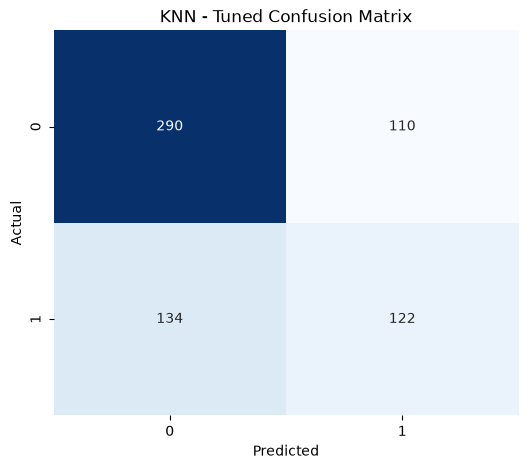

              precision    recall  f1-score   support

           0       0.68      0.72      0.70       400
           1       0.53      0.48      0.50       256

    accuracy                           0.63       656
   macro avg       0.60      0.60      0.60       656
weighted avg       0.62      0.63      0.62       656



In [54]:
best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"{best_model_name} - Tuned Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, best_pred, zero_division=0))

## 22. PCA — 3D Visualization

In [55]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

pca = PCA(n_components=3, random_state=100)
X_pca = pca.fit_transform(X_train_processed)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.13312537 0.12432158 0.11985995]
Total explained variance: 0.37730689982390375


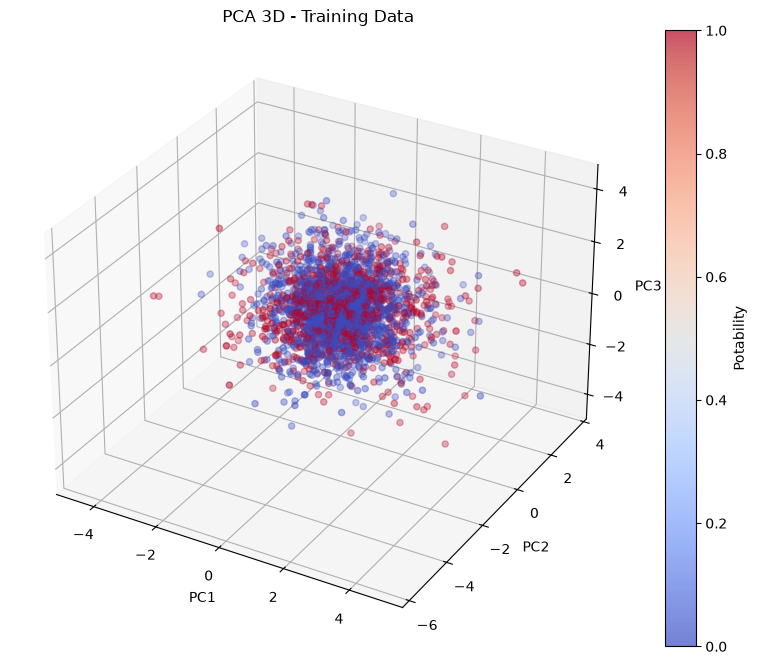

In [56]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=y_train,
    cmap="coolwarm",
    alpha=0.7
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("PCA 3D - Training Data")
plt.colorbar(scatter, ax=ax, label="Potability")
plt.show()

## 23. LDA Visualization

In [57]:
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X_train_processed, y_train)

print("LDA shape:", X_lda.shape)
print("LDA explained variance ratio:", lda.explained_variance_ratio_)

LDA shape: (2620, 1)
LDA explained variance ratio: [1.]


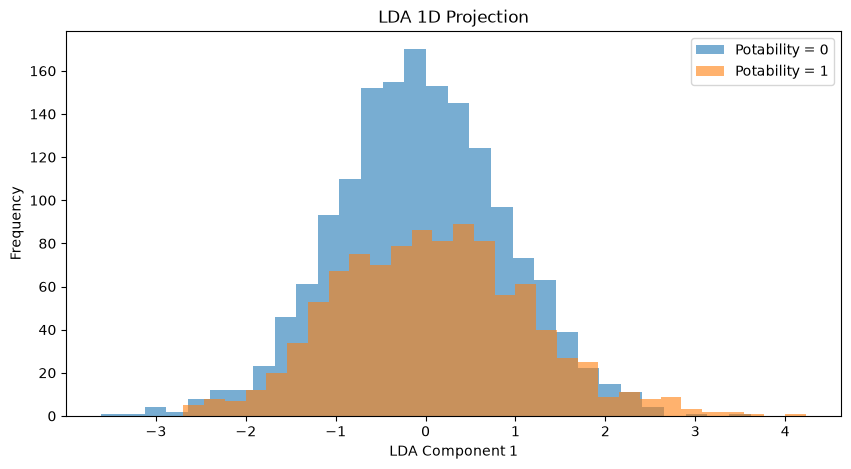

In [58]:
plt.figure(figsize=(10, 5))

for cls in sorted(y_train.unique()):
    plt.hist(
        X_lda[y_train.to_numpy() == cls, 0],
        bins=30,
        alpha=0.6,
        label=f"Potability = {cls}"
    )

plt.xlabel("LDA Component 1")
plt.ylabel("Frequency")
plt.title("LDA 1D Projection")
plt.legend()
plt.show()

## 24. LDA Dimension Check

In [59]:
print("Number of classes:", y_train.nunique())
print(
    "Maximum possible LDA components:",
    min(X_train_processed.shape[1], y_train.nunique() - 1)
)
print("For this binary dataset, maximum LDA dimensions = 1.")

Number of classes: 2
Maximum possible LDA components: 1
For this binary dataset, maximum LDA dimensions = 1.


## 25. Final Results

In [60]:
final_results = grid_results_df[
    [
        "Model",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1",
        "Test Balanced Accuracy",
        "Test ROC-AUC"
    ]
].sort_values("Test F1", ascending=False).reset_index(drop=True)

display(final_results)

,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test Balanced Accuracy,Test ROC-AUC
0,KNN,0.628049,0.525862,0.476562,0.500000,0.600781,0.651694
1,SVM,0.682927,0.650000,0.406250,0.500000,0.633125,0.718711
2,XGBoost,0.658537,0.593023,0.398438,0.476636,0.611719,0.686104
3,Decision Tree,0.567073,0.450000,0.492188,0.470149,0.553594,0.553594
4,LightGBM,0.666159,0.622517,0.367188,0.461916,0.612344,0.684492
5,Random Forest,0.675305,0.674797,0.324219,0.437995,0.612109,0.709790
6,Extra Trees,0.678354,0.702703,0.304688,0.425068,0.611094,0.712446
7,Gradient Boosting,0.653963,0.607407,0.320312,0.419437,0.593906,0.683516
8,Naive Bayes,0.626524,0.557895,0.207031,0.301994,0.551016,0.581104
9,AdaBoost,0.621951,0.750000,0.046875,0.088235,0.518437,0.554272


## 26. Save Best Model

In [61]:
import joblib

joblib.dump(best_model, "best_water_potability_model.pkl")
print("Saved: best_water_potability_model.pkl")

Saved: best_water_potability_model.pkl
